# 01 — Prepayment S-curve, estimated from pool factors

**Observation.** For pool $p$ and payoff month $t$, the monthly factors give the unscheduled paydown
after one month of scheduled amortisation at the pool WAC and WAM:

$$\text{SMM}_{p,t} = \frac{F_{t-1}(1-s_{p,t}) - F_t}{F_{t-1}(1-s_{p,t})},\qquad
s = \frac{r}{(1+r)^{n}-1},\; r=\text{WAC}/12,\; n=\text{WAM}$$

The factor published in month $M$ reflects payoffs in month $M-1$.

**Incentive.** $I_{p,t} = \text{WAC}_p - \text{PMMS}_{t-1}$, the 30-year primary mortgage rate one month
before the payoff month (borrowers lock about a month before closing).

**Model.** $\text{CPR}_p(I) = c_p + (c_{\max} - c_p)\,\big/\,\big(1+e^{-(I-I_{\text{mid}})/w}\big)$, with a
turnover floor $c_p$ for each pool and a shared refinancing response $(I_{\text{mid}}, w)$.

**Estimation.** Each month's unscheduled balance is $k = \text{SMM}\cdot n_{\text{eff}}$ payoffs out of
$n_{\text{eff}}$ effective loans. The parameters maximise the binomial quasi-likelihood. Overdispersion is
$\phi=\chi^2_{\text{Pearson}}/(N-p)$. 95% intervals come from a moving-block bootstrap over calendar months
(3-month blocks), which keeps serial correlation and the same-month correlation across pools.

All three locked pools are used. Their different coupons spread the incentive from −90 bp to +90 bp,
which is what identifies the slope.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import plot_style as ps

ps.apply()
pd.set_option("display.width", 140)
CUSIP = "3140QVLM4"

In [2]:
from run_security_analytics import estimate_prepayment, load_inputs, summarize_prepayment
from prepayment import pearson_residuals, scurve_cpr
from scipy.stats import f as f_dist

inputs = load_inputs(CUSIP)
est = estimate_prepayment(inputs, n_boot=500, seed=42)
panel, fit, draws = est["panel"], est["fit"], est["draws"]
summary = summarize_prepayment(est, CUSIP)

order = [row["cusip"] for row in inputs["config"]["securities"]]
labels = {row["cusip"]: f"{row['coupon'] * 100:.1f}% pool, WAC {est['specs'][row['cusip']].wac * 100:.2f}%"
          for row in inputs["config"]["securities"]}
print(f"Trade date {inputs['trade_date'].date()}; {len(panel)} pool-months; "
      f"months with negative unscheduled paydown: {summary['negative_smm_months']}")
panel.groupby("cusip").agg(
    months=("smm", "size"),
    first_payoff_month=("activity_month", "min"),
    last_payoff_month=("activity_month", "max"),
    incentive_min_bp=("incentive", lambda v: v.min() * 1e4),
    incentive_max_bp=("incentive", lambda v: v.max() * 1e4),
    mean_cpr_pct=("cpr", lambda v: v.mean() * 100),
).loc[order].round(1)

Trade date 2026-10-09; 75 pool-months; months with negative unscheduled paydown: 0


,months,first_payoff_month,last_payoff_month,incentive_min_bp,incentive_max_bp,mean_cpr_pct
cusip,,,,,,
3140QVLM4,25,2024-09-01,2026-09-01,-41.9,49.2,4.9
3140QVWQ3,23,2024-11-01,2026-09-01,-92.4,-1.4,3.9
3140AHRE4,27,2024-07-01,2026-09-01,1.5,92.6,17.2


In [3]:
names = fit.param_names
point = fit.natural_vector()
wald = np.sqrt(np.diag(fit.cov))
rows = []
for j, name in enumerate(names):
    lo, hi = np.percentile(draws[:, j], [2.5, 97.5])
    scale, unit = (100, "% CPR") if name.startswith("floor") else (1e4, "bp")
    rows.append({"parameter": name, "unit": unit, "estimate": point[j] * scale,
                 "wald_se": wald[j] * scale, "boot_ci_low": lo * scale, "boot_ci_high": hi * scale})
params = pd.DataFrame(rows).set_index("parameter")
print(f"ceiling c_max fixed at {fit.ceiling:.0%} (not identified, see below); phi = {fit.phi:.2f}; "
      f"log-likelihood = {fit.loglik:.2f}; N = {fit.n_obs}")
params.round(2)

ceiling c_max fixed at 50% (not identified, see below); phi = 0.95; log-likelihood = -592.74; N = 75


,unit,estimate,wald_se,boot_ci_low,boot_ci_high
parameter,,,,,
floor_3140QVLM4,% CPR,3.98,0.96,1.38,5.90
floor_3140QVWQ3,% CPR,3.87,0.75,2.03,5.17
floor_3140AHRE4,% CPR,14.79,3.60,7.38,22.96
midpoint,bp,102.19,27.25,66.14,357.92
width,bp,21.90,9.72,2.30,35.63


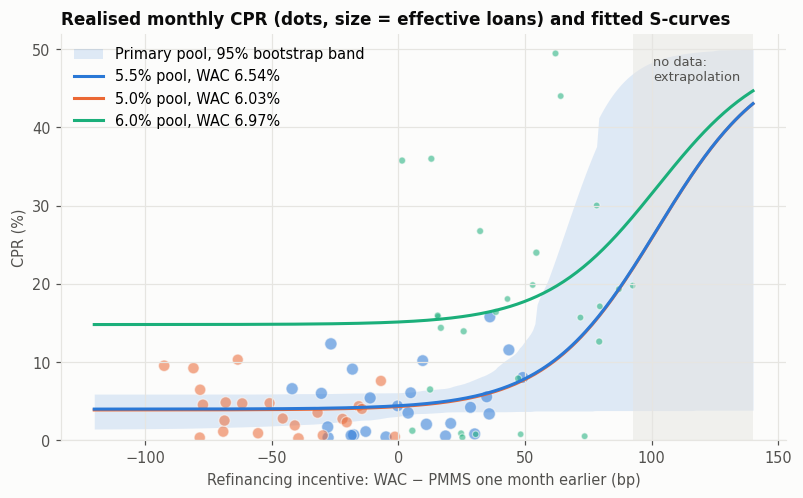

In [4]:
grid = np.linspace(-0.012, 0.014, 300)
i_floor, i_mid, i_w = names.index(f"floor_{CUSIP}"), names.index("midpoint"), names.index("width")
band = np.array([scurve_cpr(grid, d[i_floor], fit.ceiling, d[i_mid], d[i_w]) for d in draws])
lo, hi = np.percentile(band, [2.5, 97.5], axis=0)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.fill_between(grid * 1e4, lo * 100, hi * 100, color=ps.SERIES[0], alpha=0.14, linewidth=0,
                label="Primary pool, 95% bootstrap band")
for color, cusip in zip(ps.SERIES, order):
    sub = panel.loc[panel["cusip"] == cusip]
    ax.scatter(sub["incentive"] * 1e4, sub["cpr"] * 100, s=12 + sub["n_eff"] / 8, color=color,
               alpha=0.55, edgecolor=ps.SURFACE, linewidth=0.8)
    ax.plot(grid * 1e4, scurve_cpr(grid, **fit.params(cusip)) * 100, color=color, label=labels[cusip],
            zorder=4 if cusip == CUSIP else 3)
ax.axvspan(panel["incentive"].max() * 1e4, grid[-1] * 1e4, color=ps.GRID, alpha=0.5, linewidth=0)
ax.text(panel["incentive"].max() * 1e4 + 8, 46, "no data:\nextrapolation", color=ps.INK_SECONDARY, fontsize=8.5)
ax.set(xlabel="Refinancing incentive: WAC − PMMS one month earlier (bp)", ylabel="CPR (%)",
       title="Realised monthly CPR (dots, size = effective loans) and fitted S-curves", ylim=(0, 52))
ax.legend(loc="upper left")
_ = ps.save(fig, "01_scurve_fit")

### What the curve says for the primary pool

The table gives CPR at each incentive with its 95% bootstrap interval. The slope is in CPR points per 100 bp
of incentive. Inside the data (−90 bp to +90 bp) the intervals are informative. Beyond about +60 bp the band
widens to cover nearly the whole range between the floor and the ceiling.

In [5]:
pd.DataFrame({
    k: {"CPR %": v["cpr"] * 100, "CI low": v["cpr_ci95"][0] * 100, "CI high": v["cpr_ci95"][1] * 100,
        "slope (CPR pts / 100bp)": v["slope_cpr_per_100bp"] * 100,
        "slope CI low": v["slope_ci95"][0] * 100, "slope CI high": v["slope_ci95"][1] * 100}
    for k, v in summary["cpr_by_incentive_primary"].items()
}).T.round(2)

,CPR %,CI low,CI high,slope (CPR pts / 100bp),slope CI low,slope CI high
-100bp,3.98,1.47,5.90,0.02,0.0,0.38
-50bp,4.02,1.83,5.92,0.20,0.0,1.64
+0bp,4.41,3.06,6.07,1.94,0.0,7.00
+50bp,7.86,3.68,12.67,16.25,0.0,39.37
+100bp,25.84,3.79,48.32,52.42,0.0,68.22
+150bp,45.34,3.84,49.99,19.13,0.0,50.48


### Identification checks

1. **Ceiling.** Refit with $c_{\max}$ fixed at each value and compare quasi-likelihood ratios
   $2\Delta\ell/\phi$ with the 95% $F_{1,N-p}$ critical value. A flat profile means the data cannot
   pin the plateau down, because no pool was ever deep in the money. It is fixed at 50%, and notebook 04
   shows the valuation impact of 35% and 65%.
2. **Rate lag.** Lag 1 (PMMS one month before payoffs) was chosen before looking at the data. The lag 0 and
   lag 2 likelihoods are shown as a robustness check, not used for selection.
3. **Pool floors vs one pooled curve.** Quasi-LR test of the pool-specific floors.

lag log-likelihoods: {0: -593.44, 1: -592.74, 2: -591.47}
pool floors vs one pooled curve: quasi-LR = 13.33 on 2 df, p = 0.0022


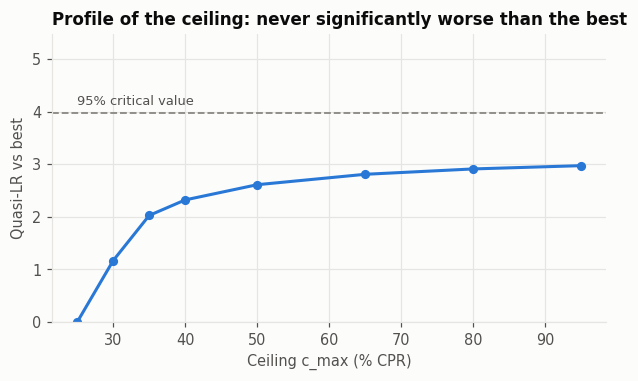

In [6]:
prof = est["ceiling_profile"]
crit = f_dist.ppf(0.95, 1, fit.n_obs - fit.n_params)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(prof["ceiling"] * 100, prof["quasi_lr"], marker="o", color=ps.SERIES[0])
ax.axhline(crit, color=ps.REFERENCE, linestyle="--", linewidth=1.2)
ax.text(prof["ceiling"].min() * 100, crit + 0.15, "95% critical value", color=ps.INK_SECONDARY, fontsize=8.5)
ax.set(xlabel="Ceiling c_max (% CPR)", ylabel="Quasi-LR vs best",
       title="Profile of the ceiling: never significantly worse than the best", ylim=(0, crit + 1.5))
_ = ps.save(fig, "01_ceiling_profile")
print("lag log-likelihoods:", {k: round(v, 2) for k, v in est["lag_loglik"].items()})
lr = summary["pool_floor_vs_pooled_quasi_lr"]
print(f"pool floors vs one pooled curve: quasi-LR = {lr:.2f} on 2 df, "
      f"p = {1 - f_dist.cdf(lr / 2, 2, fit.n_obs - fit.n_params):.4f}")

### Residual diagnostics

Pearson residuals $(\text{SMM}_{obs}-\text{SMM})/\sqrt{\text{SMM}(1-\text{SMM})/n_{\text{eff}}}$ by pool. The
bootstrap resamples blocks of calendar months because of the serial and cross-pool correlation shown below.

lag-1 autocorrelation: {'5.5% pool, WAC 6.54%': -0.17, '5.0% pool, WAC 6.03%': 0.22, '6.0% pool, WAC 6.97%': 0.15}


cusip,3140QVLM4,3140QVWQ3,3140AHRE4
cusip,,,
3140QVLM4,1.00,0.19,-0.04
3140QVWQ3,0.19,1.00,0.23
3140AHRE4,-0.04,0.23,1.00


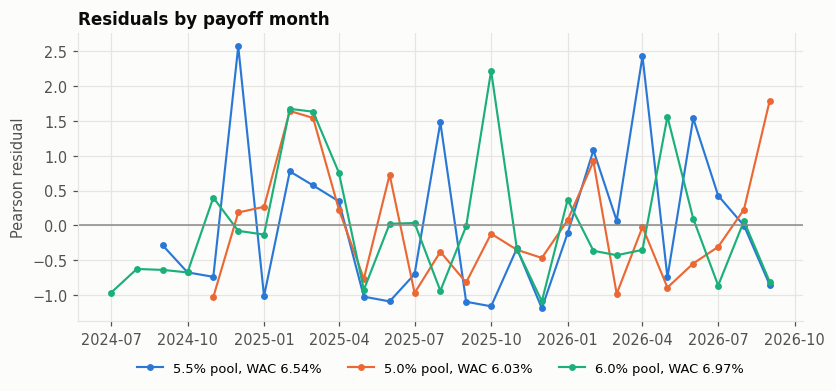

In [7]:
panel = panel.assign(pearson=pearson_residuals(panel, fit))
wide = panel.pivot(index="activity_month", columns="cusip", values="pearson")[order]
fig, ax = plt.subplots(figsize=(8.5, 3.4))
for color, cusip in zip(ps.SERIES, order):
    ax.plot(wide.index, wide[cusip], color=color, marker="o", markersize=3.5, linewidth=1.4, label=labels[cusip])
ax.axhline(0, color=ps.REFERENCE, linewidth=1)
ax.set(ylabel="Pearson residual", title="Residuals by payoff month")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=8.5)
_ = ps.save(fig, "01_residuals")
acf = {labels[c]: round(float(wide[c].dropna().autocorr(1)), 2) for c in order}
print("lag-1 autocorrelation:", acf)
wide.corr().round(2)